## Data Analysis for Parents responses 

In [1]:
#Libraries
import pandas as pd
import matplotlib.pyplot as plt
print("Matplotlib is working!")
plt.style.use("ggplot")

Matplotlib is working!


In [2]:
#Loading the data

df = pd.read_csv("../data/parent.csv", encoding="utf-8")
df.head()

,Which stakeholder are you?,"Is your child currently receiving, waiting for, or has previously received Speech and Language Therapy (SaLT)?","Who, in relation to the child, is filling out this questionnaire? - Selected Choice",Where are you based? - Selected Choice,What is your work status? - Selected Choice,What is your work status? - Other - Text,How old is your child?,Has your child received any of the following diagnoses? (select all that apply) - Selected Choice,Has your child received any of the following diagnoses? (select all that apply) - Other (Please specify) - Text,How does your child mainly communicate? (select all that apply) - Selected Choice,...,Has supporting your child's SaLT or wider needs affected your work or income?,"Of the gaps below, which of the three affect your family most? Please select your top 3. - Selected Choice","Of the gaps below, which of the three affect your family most? Please select your top 3. - Other (please specify) - Text",What concerns or hesitations do you have about using digital tools to support your child's SaLT? (please select all that apply) - Selected Choice,What concerns or hesitations do you have about using digital tools to support your child's SaLT? (please select all that apply) - Other (please specify) - Text,"If a digital tool existed to support your child's SaLT, when in your journey would it be most useful? - Selected Choice","If a digital tool existed to support your child's SaLT, when in your journey would it be most useful? - Other (please specify) - Text",Anything else you would like us to know?,"Finally, would you be interested in having a quick chat to help us improve our research? - Selected Choice","Finally, would you be interested in having a quick chat to help us improve our research? - Yes (please provide your email address) - Text"
0,Parent or Caregiver,"Yes — currently receiving SaLT (NHS, private, ...",Mother,London,Other,Not working due time caring,11-16,"Autism / Autism Spectrum Condition,Other neuro...",\n,Mostly using spoken sentences,...,No impact,"Long wait for first SaLT appointment,Lack of g...",\n,None — I'd be open to trying one,\n,Between active sessions,\n,My child's SALT is via her school as attends a...,No,\n
1,Parent or Caregiver,"Yes — currently receiving SaLT (NHS, private, ...",Mother,Rest of England,Other,35hours carer,0-5,"Autism / Autism Spectrum Condition,Development...","adhd ,pda","Mainly non-verbal / very few words,Uses an AAC...",...,I have stopped working entirely,"Long wait for first SaLT appointment,Lack of g...",funded effect support,"Privacy and data protection for my child,Too m...",tammystrange33@yahoo.com senenterrise spealist...,Other (please specify),"disability advocate, training government elect...",\n,\n,\n
2,Parent or Caregiver,"Yes — currently receiving SaLT (NHS, private, ...",Mother,Outside of the UK,Self-employed,\n,5-10,"Autism / Autism Spectrum Condition,Other neuro...",\n,"Mainly non-verbal / very few words,Uses an AAC...",...,\n,\n,\n,\n,\n,\n,\n,\n,\n,\n
3,Parent or Caregiver,"Yes — currently receiving SaLT (NHS, private, ...",Mother,Rest of England,Part-time,\n,0-5,\n,\n,"Mainly non-verbal / very few words,Other (plea...",...,I have reduced my working hours,"Long wait for first SaLT appointment,Lack of g...",\n,"Too much screen time for my child,It can't rep...",\n,While waiting for the first SaLT appointment,\n,\n,No,\n
4,Parent or Caregiver,"Yes — currently receiving SaLT (NHS, private, ...",Mother,Rest of England,Other,\n,17 +,\n,\n,\n,...,\n,\n,\n,\n,\n,\n,\n,\n,\n,\n


In [3]:
# Verify the dataframe
df.shape

(42, 30)

In [4]:
pd.set_option("display.max_rows", None)
pd.Series(df.columns)

0                            Which stakeholder are you?
1     Is your child currently receiving, waiting for...
2     Who, in relation to the child, is filling out ...
3                Where are you based? - Selected Choice
4           What is your work status? - Selected Choice
5              What is your work status? - Other - Text
6                                How old is your child?
7     Has your child received any of the following d...
8     Has your child received any of the following d...
9     How does your child mainly communicate? (selec...
10    How does your child mainly communicate? (selec...
11    How often do you currently have direct contact...
12    How often do you currently have direct contact...
13    How emotionally supported do you feel as a par...
14    Therapists often provide homework for their cl...
15    Did your therapist explain the purpose of the ...
16    Between SaLT sessions, who is expected to deli...
17    Between SaLT sessions, who is expected to 

A total of 34 parent/carer responses were collected through the questionnaire. However, several questions contained substantial missing data, with approximately three responses omitted across many demographic questions and considerably more for questions that were only applicable to specific participant groups

In [5]:
# Clean common Qualtrics artefacts

df = df.replace(r"^\s*\\n\s*$", pd.NA, regex=True)
df = df.replace(r"^\s*$", pd.NA, regex=True)
df = df.replace("nan", pd.NA)
df = df.replace("None", pd.NA)

#### Helper Functions

In [6]:
def clean_response(x):
    x = str(x).strip()

    if x in ["", "-", "\\n", "\n", "nan", "None"]:
        return None

    # Fix Qualtrics encoding
    x = x.replace("â€“", "–")
    x = x.replace("â€”", "—")
    x = x.replace("â€", "")
    x = x.replace("Â", "")

    return x

    return x
def plot_single_choice(column, title, order=None, exclude_blank=True):
    data = df[column].apply(clean_response)

    blank_count = data.isna().sum()

    if exclude_blank:
        data = data.dropna()
    else:
        data = data.fillna("Blank")

    counts = data.value_counts()

    if order:
        counts = counts.reindex(order, fill_value=0)
        counts = counts[counts > 0]
    else:
        counts = counts.sort_values()

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.barh(counts.index, counts.values)

    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.1, bar.get_y() + bar.get_height()/2, int(width), va="center", fontweight="bold")

    ax.set_title(title, fontsize=18, fontweight="bold", pad=15)
    ax.set_xlabel("Number of Participants")
    ax.set_ylabel("")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

    print(f"Blank responses excluded: {blank_count}")


def plot_multiple_choice(column, title, exclude_values=None):
    if exclude_values is None:
        exclude_values = ["", "-", "Other (please specify)", "\\n", "\n", "nan", "None"]

    data = (
        df[column]
        .dropna()
        .astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )

    data = data[~data.isin(exclude_values)]

    counts = data.value_counts().sort_values()

    fig, ax = plt.subplots(figsize=(10, 6))

    bars = ax.barh(counts.index, counts.values)

    for bar in bars:
        width = bar.get_width()
        ax.text(width + 0.1, bar.get_y() + bar.get_height()/2, int(width), va="center", fontweight="bold")

    ax.set_title(title, fontsize=18, fontweight="bold", pad=15)
    ax.set_xlabel("Number of Participants")
    ax.set_ylabel("")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

#### Parents Demographics

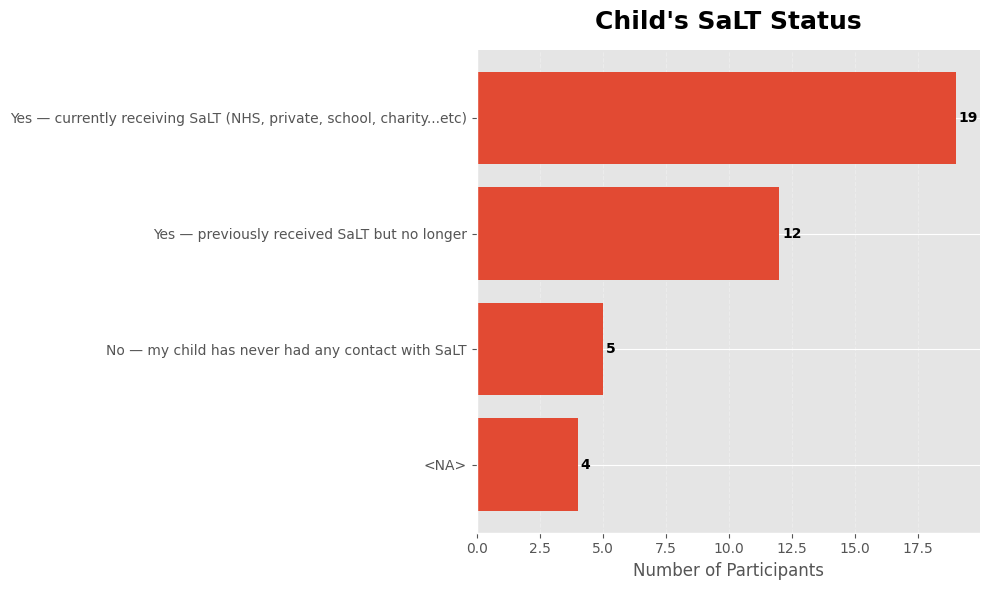

Blank responses excluded: 2


In [7]:
plot_single_choice(
    "Is your child currently receiving, waiting for, or has previously received Speech and Language Therapy (SaLT)?",
    "Child's SaLT Status"
)

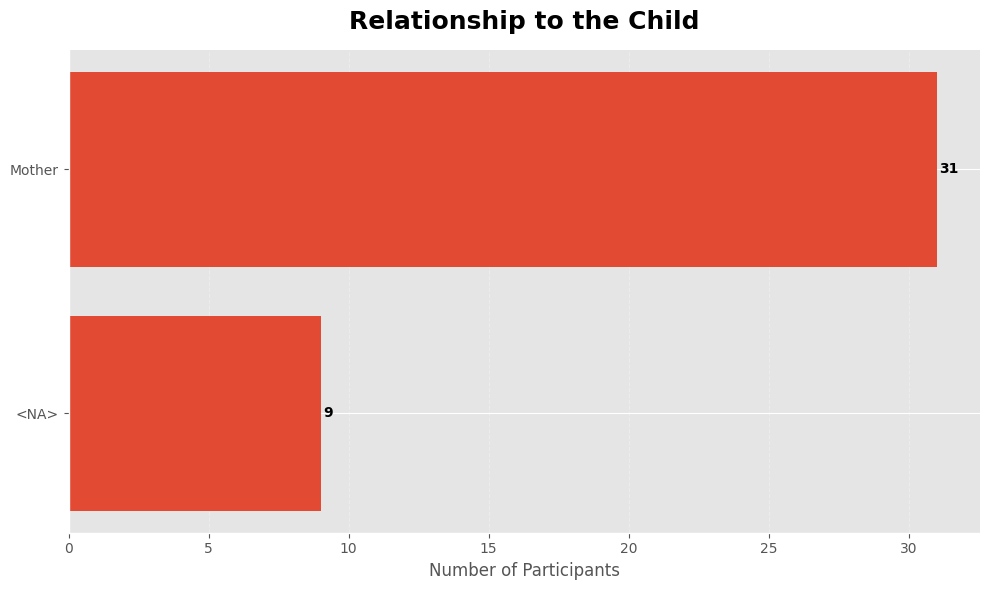

Blank responses excluded: 2


In [8]:
plot_single_choice(
    "Who, in relation to the child, is filling out this questionnaire? - Selected Choice",
    "Relationship to the Child"
)

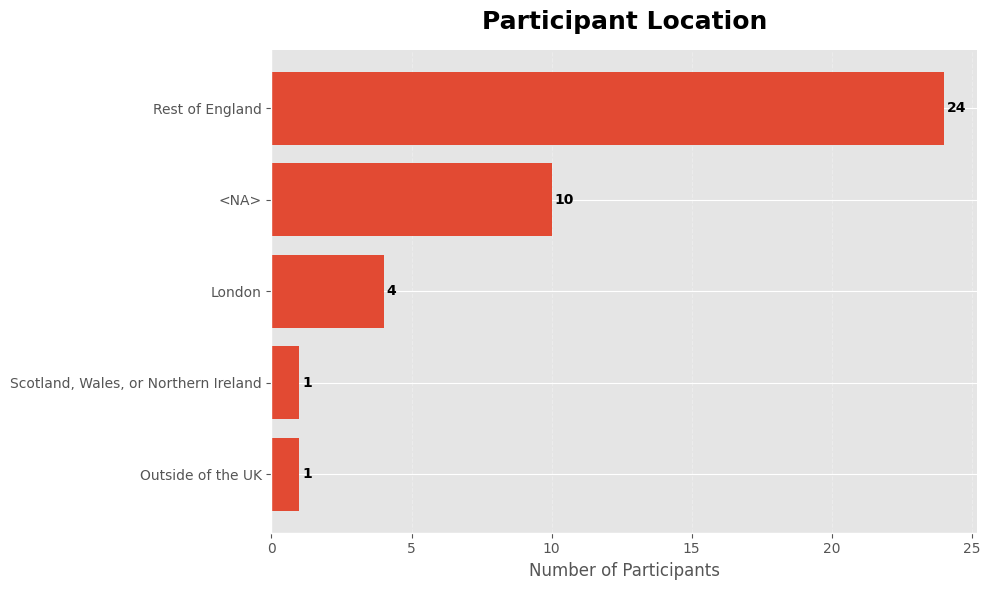

Blank responses excluded: 2


In [9]:
plot_single_choice(
    "Where are you based? - Selected Choice",
    "Participant Location"
)

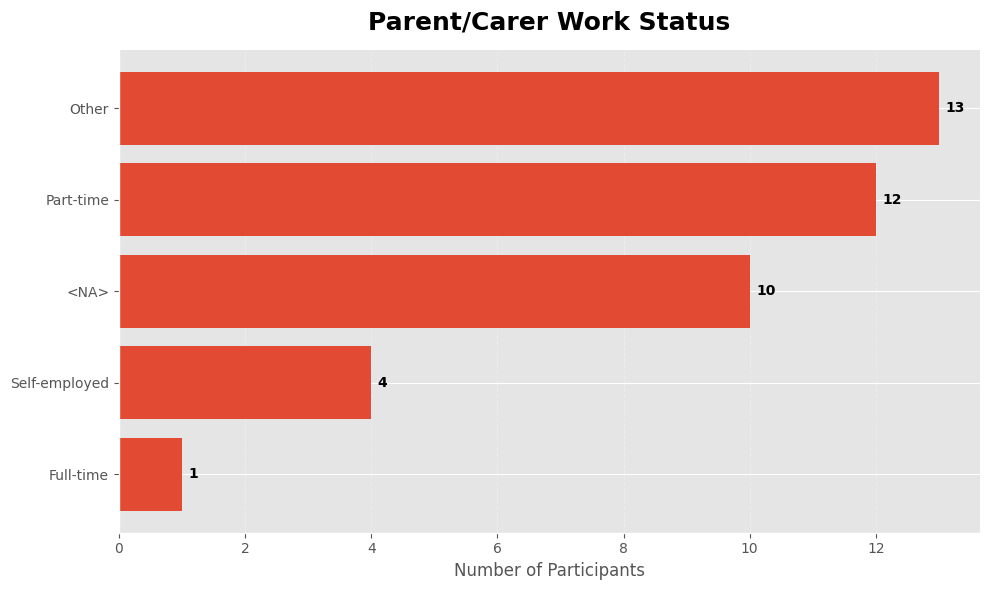

Blank responses excluded: 2


In [10]:
plot_single_choice(
    "What is your work status? - Selected Choice",
    "Parent/Carer Work Status"
)

Most respondents were parents or primary caregivers, with mothers accounting for the overwhelming majority of completed responses. This indicates that maternal perspectives were predominantly represented within the sample. Geographically, most participants were based in the rest of England, while relatively few respondents came from London or Scotland, Wales and Northern Ireland. Employment status varied, although many participants reported either part-time employment or selected an alternative employment category, suggesting diverse family and caregiving circumstances.

##### Child Demographics

In [11]:
df["How old is your child?"].value_counts(dropna=False)

How old is your child?
5-10      13
<NA>      10
11-16      7
17 +       5
0-5        3
NaN        2
5-10       1
17 +       1
Name: count, dtype: int64

#### Child characteristics

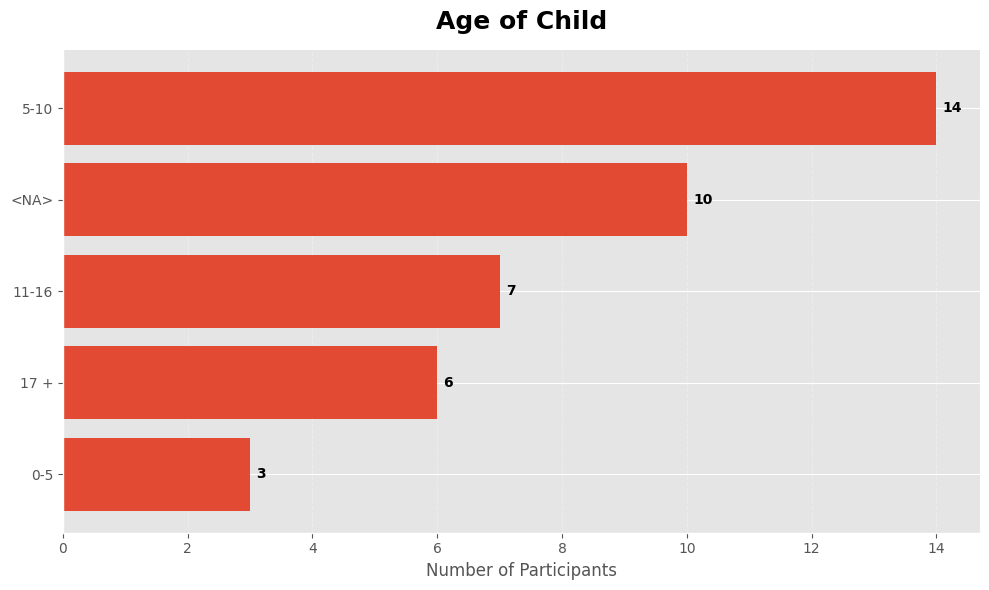

Blank responses excluded: 2


In [12]:
plot_single_choice(
    "How old is your child?",
    "Age of Child"
)

Regarding children represented in the survey, the largest group were aged 5–10 years, followed by 11–16 years, with only a small number of respondents reporting children aged 18 years or older. This distribution suggests that the survey largely reflects experiences of families with primary and secondary school-aged children.

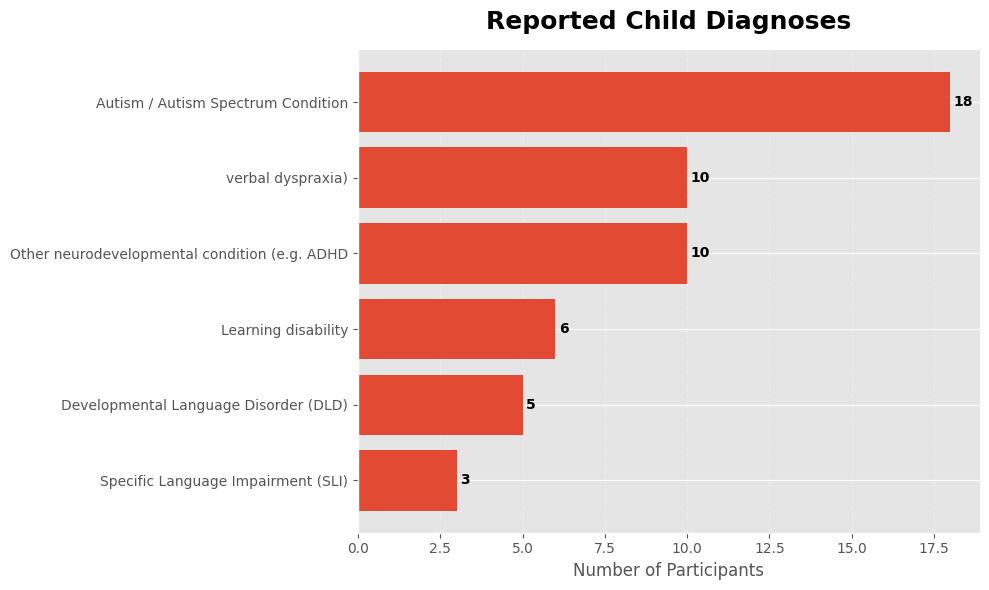

In [13]:
plot_multiple_choice(
    "Has your child received any of the following diagnoses? (select all that apply) - Selected Choice",
    "Reported Child Diagnoses"
)

Autism Spectrum Condition (ASC) was the most frequently reported diagnosis, identified by eight respondents. Other commonly reported diagnoses included verbal dyspraxia, other neurodevelopmental conditions such as ADHD, and Developmental Language Disorder (DLD). Smaller numbers reported learning disability or Specific Language Impairment (SLI). Because respondents could select multiple diagnoses, these categories are not mutually exclusive and reflect the high prevalence of co-occurring developmental conditions within the sample.

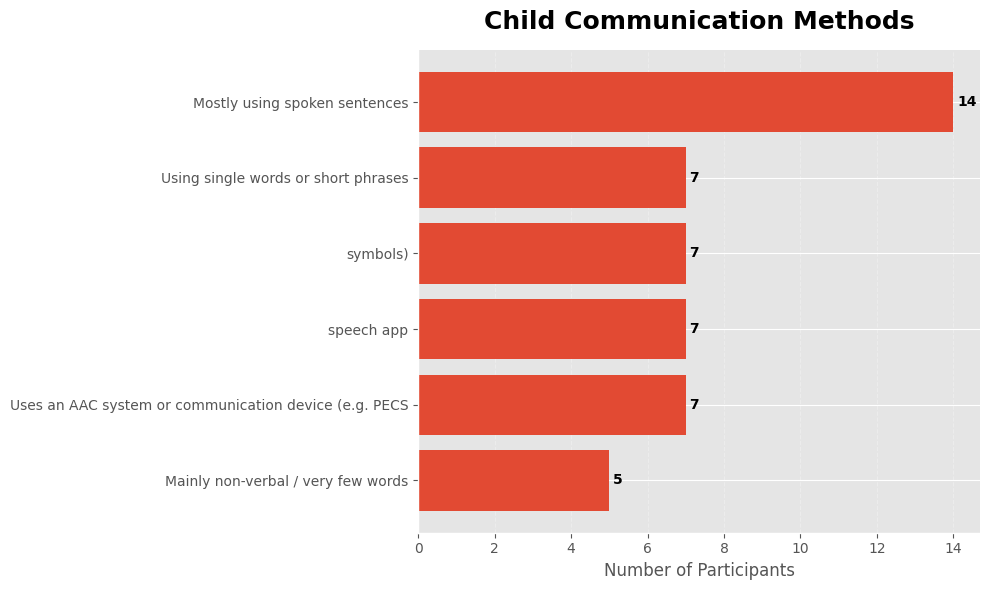

In [14]:
plot_multiple_choice(
    "How does your child mainly communicate? (select all that apply) - Selected Choice",
    "Child Communication Methods"
)

Communication abilities also varied considerably. The most commonly reported communication method was using spoken sentences, followed by single words or short phrases. Several children reportedly used augmentative and alternative communication (AAC) systems, communication applications, or visual symbols, while a smaller number were described as mainly non-verbal. These findings demonstrate substantial heterogeneity in communication profiles among participating families.

## Therapy Experience


In [15]:
[col for col in df.columns if "direct contact" in col.lower()]

["How often do you currently have direct contact with your child's SaLT therapist (in person, phone, video, or email)? - Selected Choice",
 "How often do you currently have direct contact with your child's SaLT therapist (in person, phone, video, or email)? - Other (please specify) - Text"]

In [16]:
df["How often do you currently have direct contact with your child's SaLT therapist (in person, phone, video, or email)? - Selected Choice"].value_counts(dropna=False)

How often do you currently have direct contact with your child's SaLT therapist (in person, phone, video, or email)? - Selected Choice
<NA>                                                         17
Other (please specify)                                        7
Not applicable — we have been discharged from the service     7
Around once a month                                           3
At least once a week                                          3
Never                                                         2
NaN                                                           2
We have had no contact since our first appointment            1
Name: count, dtype: int64

In [17]:
for i, col in enumerate(df.columns):
    print(i, col)

0 Which stakeholder are you?
1 Is your child currently receiving, waiting for, or has previously received Speech and Language Therapy (SaLT)?
2 Who, in relation to the child, is filling out this questionnaire? - Selected Choice
3 Where are you based? - Selected Choice
4 What is your work status? - Selected Choice
5 What is your work status? - Other - Text
6 How old is your child?
7 Has your child received any of the following diagnoses? (select all that apply) - Selected Choice
8 Has your child received any of the following diagnoses? (select all that apply) - Other (Please specify) - Text
9 How does your child mainly communicate? (select all that apply) - Selected Choice
10 How does your child mainly communicate? (select all that apply) - Other (please specify) - Text
11 How often do you currently have direct contact with your child's SaLT therapist (in person, phone, video, or email)? - Selected Choice
12 How often do you currently have direct contact with your child's SaLT therapist

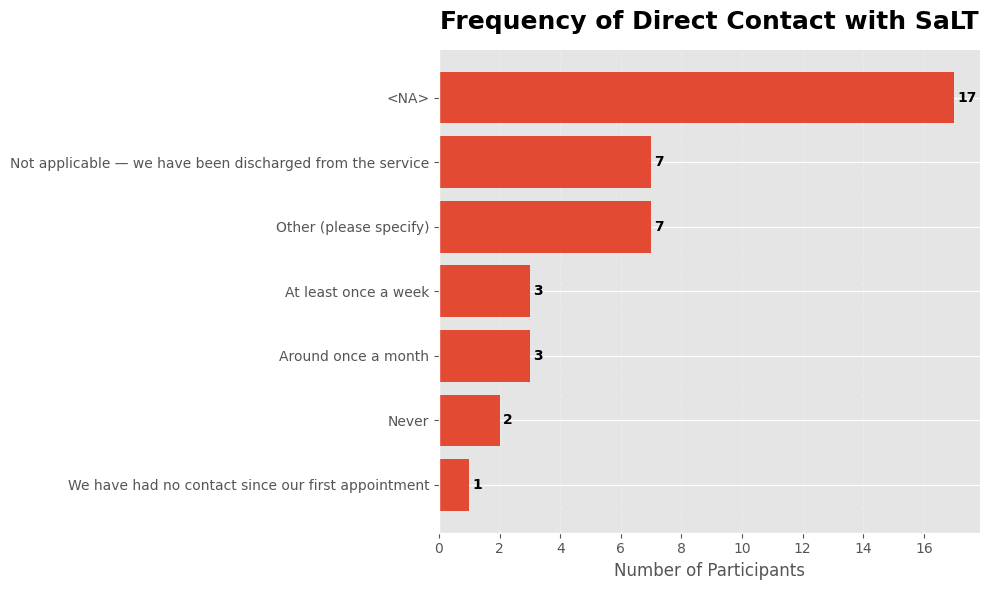

Blank responses excluded: 2


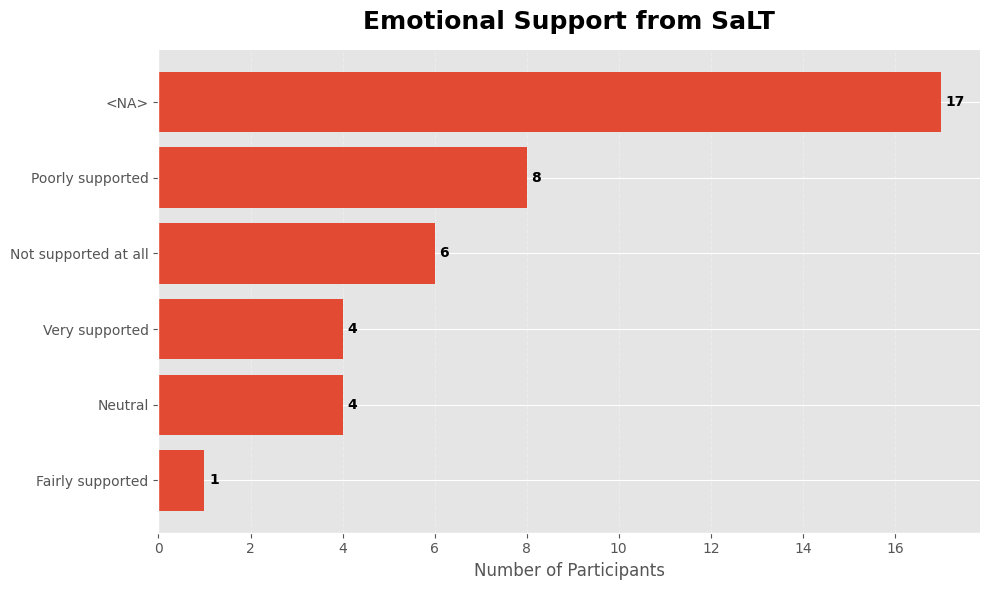

Blank responses excluded: 2


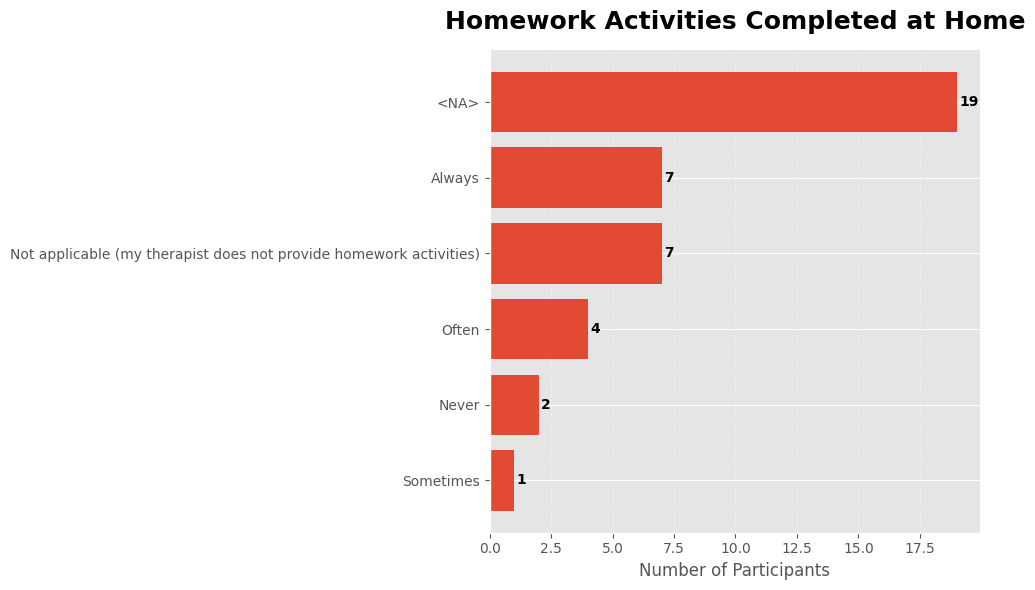

Blank responses excluded: 2


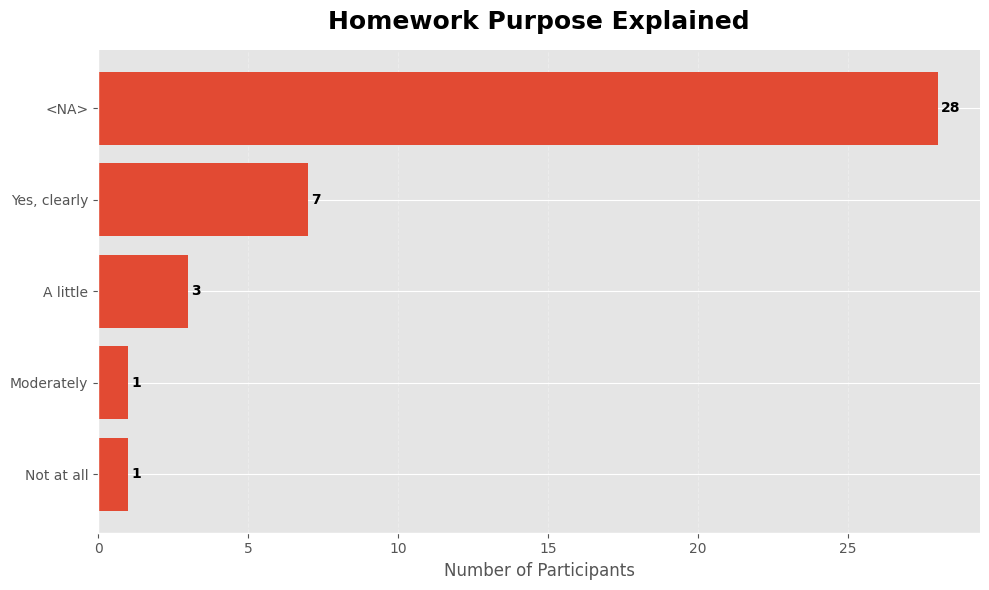

Blank responses excluded: 2


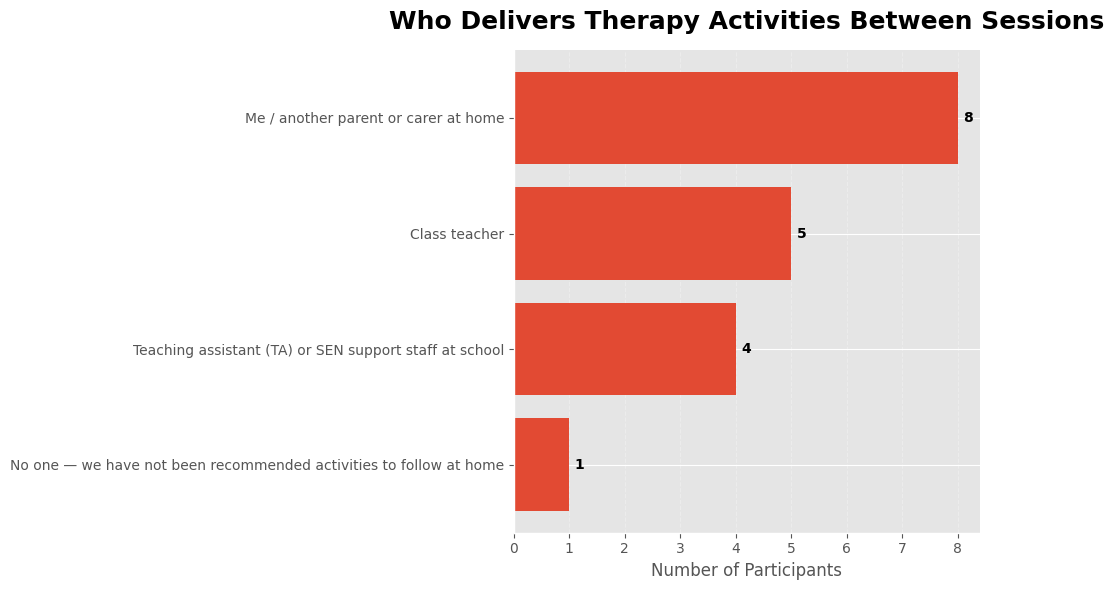

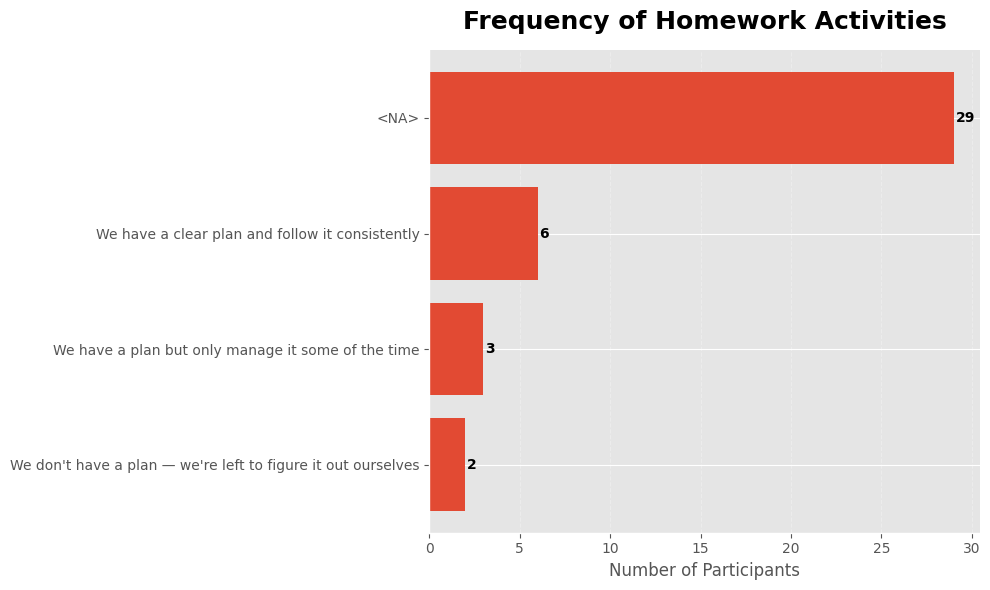

Blank responses excluded: 2


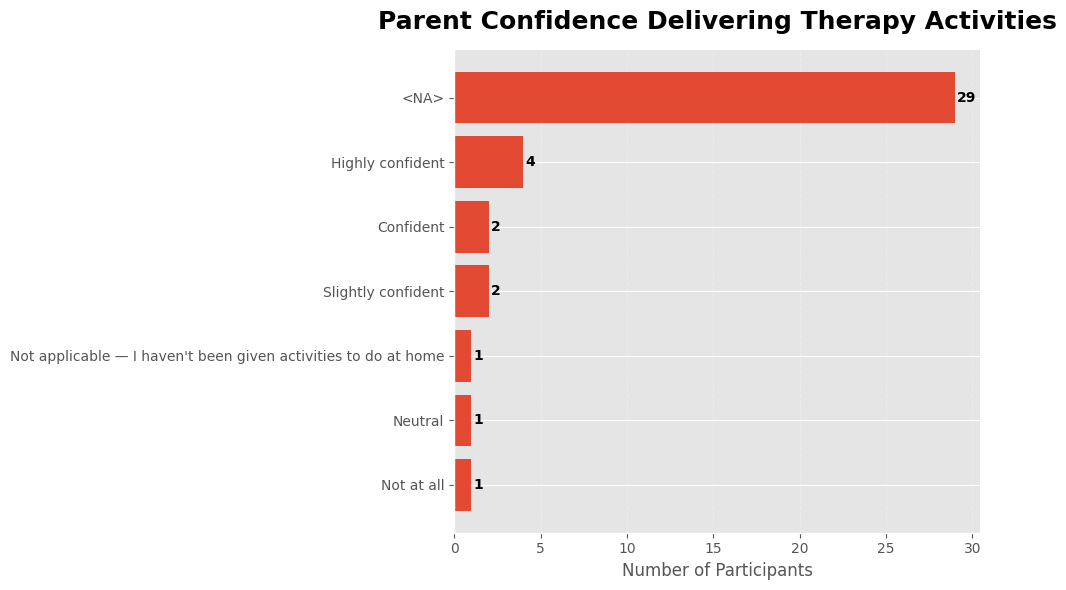

Blank responses excluded: 2


In [18]:
# Direct contact frequency
plot_single_choice(
    "How often do you currently have direct contact with your child's SaLT therapist (in person, phone, video, or email)? - Selected Choice",
    "Frequency of Direct Contact with SaLT"
)


# Emotional support
plot_single_choice(
    "How emotionally supported do you feel as a parent/carer in managing your child's speech, language and communication needs?",
    "Emotional Support from SaLT"
)

# Homework provided
plot_single_choice(
     "Therapists often provide homework for their clients. Do you conduct intervention activities at home?",
    "Homework Activities Completed at Home"
)

# Homework explained
plot_single_choice(
    "Did your therapist explain the purpose of the activities — why you're doing them and what they're working towards?",
    "Homework Purpose Explained"

)

# Who delivers homework
plot_multiple_choice(
    "Between SaLT sessions, who is expected to deliver the therapist's recommended activities? (select all that apply) - Selected Choice",
    "Who Delivers Therapy Activities Between Sessions"
)

# Weekly homework time
plot_single_choice(
    "Think about a typical week between your child's SaLT sessions. How often do the recommended activities actually happen?",
    "Frequency of Homework Activities"
)

# Parent confidence
plot_single_choice(
    "How confident do you feel delivering SaLT activities your therapist has recommended at home?",
    "Parent Confidence Delivering Therapy Activities"
)

#### Contact with Speech and Language Therapists
Among respondents who answered the question, direct contact with therapists appeared relatively limited. Only a small number reported communicating with their child's therapist at least once per week or around once per month, while several respondents indicated that the question was not applicable because their child had already been discharged from services. This variation reflects differing levels of ongoing clinical involvement among participating families. 

#### Emotional Support
Parents reported mixed experiences regarding emotional support received through SaLT services. Responses ranged from very supported to not supported at all, although more respondents selected categories reflecting poor or absent emotional support than positive experiences. This suggests variability in how supported families feel while managing their child's communication needs alongside therapy.

#### Home Therapy Activities
Parents demonstrated relatively high engagement with therapy activities at home. Among applicable responses, the majority reported always completing homework activities, while smaller numbers indicated completing them often or sometimes. Only one respondent reported never completing recommended activities. These findings suggest that participating parents generally attempted to implement therapist recommendations outside clinical sessions when provided with them


## Impact on Families

This section examines how accessing SaLT has affected families, including work commitments, financial pressures, and perceived gaps in support.


#### Impact on Families

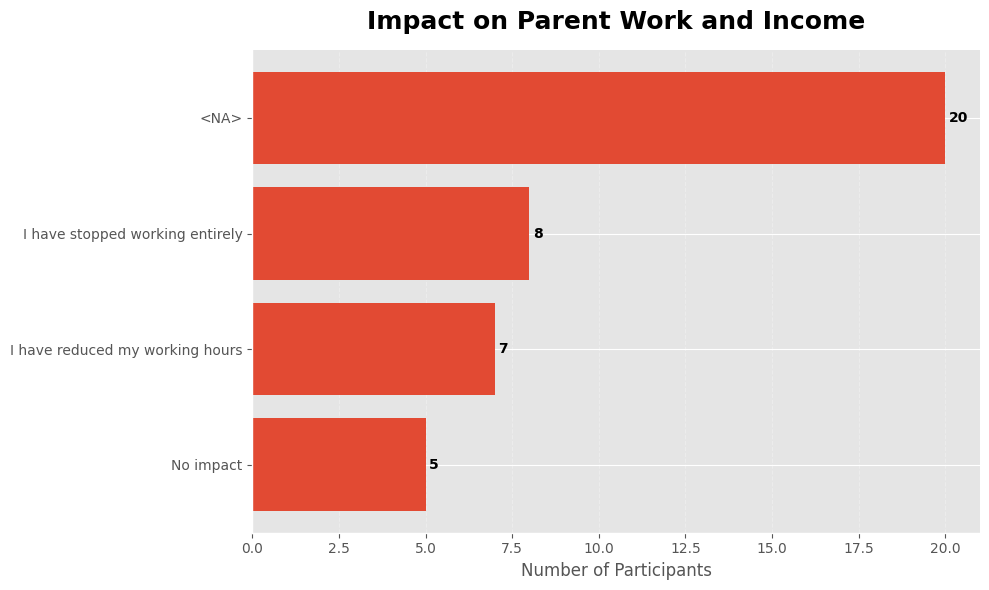

Blank responses excluded: 2


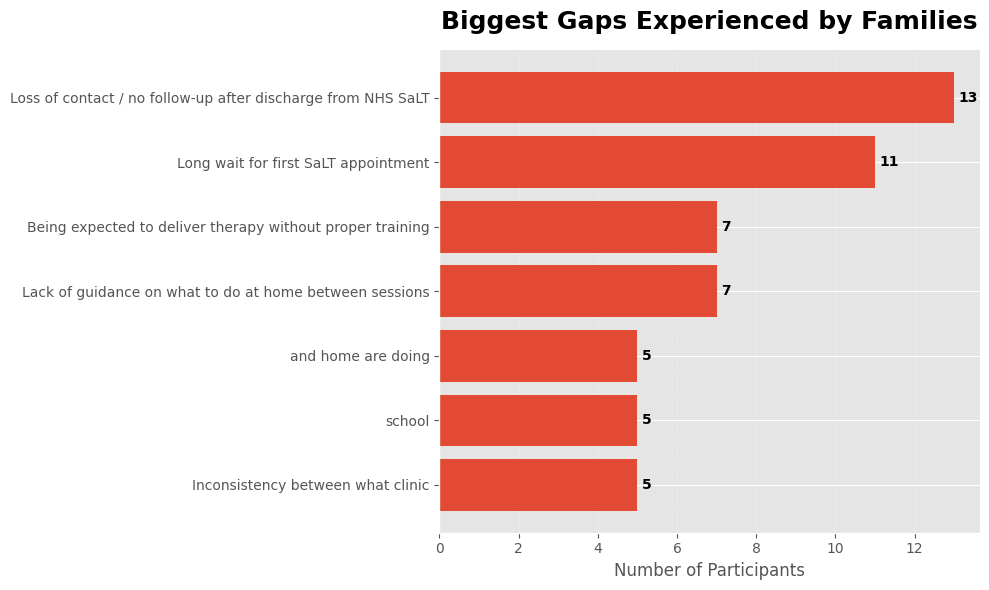

In [19]:
# Effect on work 
plot_single_choice(
    "Has supporting your child's SaLT or wider needs affected your work or income?",
    "Impact on Parent Work and Income"
)
#Biggest gaps
plot_multiple_choice(
    "Of the gaps below, which of the three affect your family most? Please select your top 3. - Selected Choice",
    "Biggest Gaps Experienced by Families"
)



#### Digital Technology 

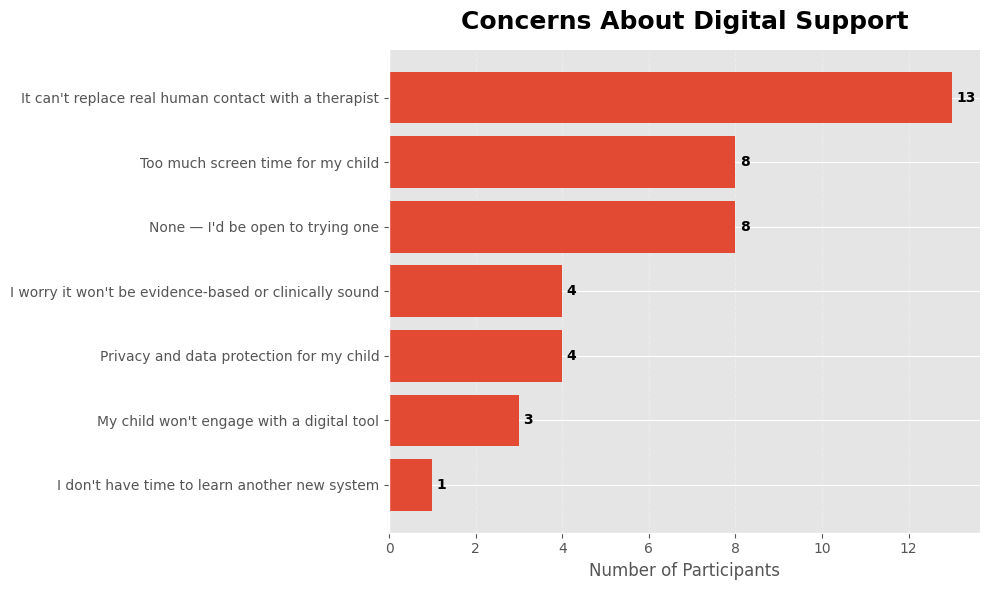

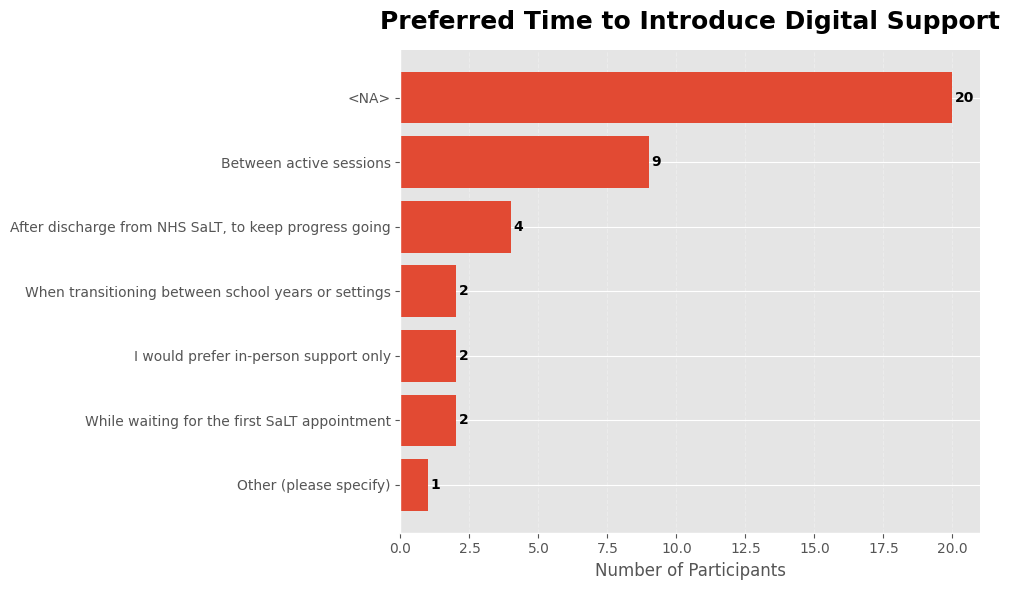

Blank responses excluded: 2


In [20]:
# Concerns about digital tools
plot_multiple_choice(
    "What concerns or hesitations do you have about using digital tools to support your child's SaLT? (please select all that apply) - Selected Choice",
    "Concerns About Digital Support"
)
#Best stage for digital support 
plot_single_choice(
    "If a digital tool existed to support your child's SaLT, when in your journey would it be most useful? - Selected Choice",
    "Preferred Time to Introduce Digital Support"
)


# Open Responses 

In [21]:
### Extract all open-text responses
open_cols = [
    "What concerns or hesitations do you have about using digital tools to support your child's SaLT? (please select all that apply) - Other (please specify) - Text",
    "Anything else you would like us to know?",
    "How has the wait affected your child or your family?"
]

for col in open_cols:
    if col in df.columns:
        print("\n" + "="*100)
        print(col)
        print("="*100)

        responses = (
            df[col]
            .dropna()
            .astype(str)
            .str.strip()
        )

        responses = responses[
            ~responses.isin(["", "\\n", "\n", "-", "nan", "None"])
        ]

        for i, r in enumerate(responses, 1):
            print(f"{i}. {r}\n")


What concerns or hesitations do you have about using digital tools to support your child's SaLT? (please select all that apply) - Other (please specify) - Text
1. tammystrange33@yahoo.com senenterrise spealist future traveller lifedisability coparte government chairman ceodlacultural legal aid access  mandatory business,scheme petition funded celebrity company, benefits lifetime, family authority

2. Only if it follows a set path of development and doesn't rely on parent working out what to do next for the situation


Anything else you would like us to know?
1. My child's SALT is via her school as attends an independent specialist school.

2. Our experience is a good one because we’ve been using a private SLT for over 4 years. Our NHS experience was terrible, 18 month wait to be signed off after a phone call and never meeting our then very minimally speaking child because they discovered we had paid to complete the more than words course (plus they didn’t recognise he was then a stage

In [22]:
### Summary of themes

# Display full text in notebook
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 2000)

themes = pd.DataFrame({

    "Initial Codes": [

        "Long waiting times; NHS delays; lack of access; private therapy",

        "Private assessment; financial sacrifice; paying for therapy",

        "Recommendations ignored; reasonable adjustments not implemented; educational barriers",

        "Specialist expertise; individualised care; condition-specific support",

        "Structured guidance; evidence-based digital support; parent confidence",

        "Positive therapist relationships; personalised care; evidence-based recommendations"

    ],

    "Theme": [

        "Limited NHS access",

        "Financial burden of private therapy",

        "Failure to implement recommendations",

        "Need for specialist and individualised care",

        "Structured digital support",

        "Value of individual therapists"

    ],

    "Description": [

        "Parents described long waiting times, lack of specialist NHS provision, and delays in accessing Speech and Language Therapy services.",

        "Several families reported paying privately for therapy or assessments because appropriate NHS services were unavailable, often making considerable financial sacrifices.",

        "Parents reported that professional Speech and Language Therapy recommendations were frequently ignored or not implemented within healthcare and educational settings.",

        "Participants emphasised the importance of specialist knowledge and interventions tailored to their child's communication profile and diagnosis.",

        "Parents expressed interest in digital technologies provided they offered structured, evidence-based guidance rather than requiring parents to determine intervention independently.",

        "Despite criticism of wider services, several parents described highly positive experiences with individual Speech and Language Therapists."

    ],

    "Supporting Evidence (Participant Quote)": [

        """Our NHS experience was terrible, 18 month wait to be signed off after a phone call and never meeting our then very minimally speaking child because they discovered we had paid to complete the More Than Words course.""",

        """I feel lucky to have had 5 years of private therapy with an incredible therapist. We couldn't ever afford it, spent our house deposit and continued to rent because our child's communication is more important and he is thriving. The NHS completely failed him and it makes me very sad to think of all the other children the NHS simply cannot see to because of the demand and burn out on therapists.""",

        """The Local Authority has consistently failed to provide the educational provision recommended and has repeatedly disregarded her communication profile. A similar pattern is evident within NHS services. My child's Speech and Language Therapy recommendations and communication profile have not been respected, and reasonable adjustments have frequently not been implemented.""",

        """There is no NHS support in some areas for Selective Mutism. There is no guidance or route to diagnosis and parents are forced to go private for assessment.""",

        """Only if it follows a set path of development and doesn't rely on parent working out what to do next for the situation.""",

        """My child has an excellent Speech and Language Therapist whose recommendations are detailed, evidence-based and specifically tailored to her neurodevelopmental profile."""

    ]

})

themes.style.set_properties(**{
    "text-align": "left",
    "white-space": "pre-wrap"
}).set_table_styles([
    {
        "selector": "th",
        "props": [
            ("font-size", "13pt"),
            ("font-weight", "bold"),
            ("text-align", "center")
        ]
    },
    {
        "selector": "td",
        "props": [
            ("font-size", "11pt"),
            ("vertical-align", "top"),
            ("padding", "8px")
        ]
    }
])

,Initial Codes,Theme,Description,Supporting Evidence (Participant Quote)
0,Long waiting times; NHS delays; lack of access; private therapy,Limited NHS access,"Parents described long waiting times, lack of specialist NHS provision, and delays in accessing Speech and Language Therapy services.","Our NHS experience was terrible, 18 month wait to be signed off after a phone call and never meeting our then very minimally speaking child because they discovered we had paid to complete the More Than Words course."
1,Private assessment; financial sacrifice; paying for therapy,Financial burden of private therapy,"Several families reported paying privately for therapy or assessments because appropriate NHS services were unavailable, often making considerable financial sacrifices.","I feel lucky to have had 5 years of private therapy with an incredible therapist. We couldn't ever afford it, spent our house deposit and continued to rent because our child's communication is more important and he is thriving. The NHS completely failed him and it makes me very sad to think of all the other children the NHS simply cannot see to because of the demand and burn out on therapists."
2,Recommendations ignored; reasonable adjustments not implemented; educational barriers,Failure to implement recommendations,Parents reported that professional Speech and Language Therapy recommendations were frequently ignored or not implemented within healthcare and educational settings.,"The Local Authority has consistently failed to provide the educational provision recommended and has repeatedly disregarded her communication profile. A similar pattern is evident within NHS services. My child's Speech and Language Therapy recommendations and communication profile have not been respected, and reasonable adjustments have frequently not been implemented."
3,Specialist expertise; individualised care; condition-specific support,Need for specialist and individualised care,Participants emphasised the importance of specialist knowledge and interventions tailored to their child's communication profile and diagnosis.,There is no NHS support in some areas for Selective Mutism. There is no guidance or route to diagnosis and parents are forced to go private for assessment.
4,Structured guidance; evidence-based digital support; parent confidence,Structured digital support,"Parents expressed interest in digital technologies provided they offered structured, evidence-based guidance rather than requiring parents to determine intervention independently.",Only if it follows a set path of development and doesn't rely on parent working out what to do next for the situation.
5,Positive therapist relationships; personalised care; evidence-based recommendations,Value of individual therapists,"Despite criticism of wider services, several parents described highly positive experiences with individual Speech and Language Therapists.","My child has an excellent Speech and Language Therapist whose recommendations are detailed, evidence-based and specifically tailored to her neurodevelopmental profile."


# Overall 
Collectively, the findings demonstrate that families participating in the survey represent a broad range of therapy experiences and communication needs. The sample was characterised primarily by parents of school-aged autistic children, many of whom remained actively involved in delivering therapy activities at home. Parents appeared willing to engage with home programmes, although the frequency of therapist contact and perceived emotional support varied considerably. Furthermore, the results emphasise the central role parents play in continuing intervention beyond formal clinical sessions, highlighting their importance within the wider Speech and Language Therapy pathway.
